# LeetCode #160: Intersection of Two Linked Lists

https://leetcode.com/problems/intersection-of-two-linked-lists/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Hash Set | O(m+n) | O(m) |
| Two Pointers ★ | O(m+n) | O(1) |

## Understanding the Methods
### Hash Set
Store all nodes of list A in a set. Traverse list B; first node found in the set is the intersection. O(m) space.

### Optimal: Two Pointers ★
Two pointers, pA starting at headA and pB starting at headB. Advance each; when one reaches null, redirect it to the other list's head. They will meet at the intersection (or both reach null if no intersection). This works because both pointers travel the same total distance: len(A) + len(B).

## Solutions
### C#

In [ ]:
public class ListNode { public int val; public ListNode next; public ListNode(int x) { val = x; } }

public class Solution {
    public ListNode GetIntersectionNode(ListNode headA, ListNode headB) {
        var a = headA;
        var b = headB;
        while (a != b) {
            a = a == null ? headB : a.next;
            b = b == null ? headA : b.next;
        }
        return a;
    }
}

### Python

In [ ]:
class ListNode:
    def __init__(self, x):
        self.val = x
        self.next = None

class Solution:
    def getIntersectionNode(self, headA: ListNode, headB: ListNode) -> ListNode:
        a, b = headA, headB
        while a is not b:
            a = headB if a is None else a.next
            b = headA if b is None else b.next
        return a

### Go

In [ ]:
package main

type ListNode struct {
    Val  int
    Next *ListNode
}

func getIntersectionNode(headA, headB *ListNode) *ListNode {
    a, b := headA, headB
    for a != b {
        if a == nil {
            a = headB
        } else {
            a = a.Next
        }
        if b == nil {
            b = headA
        } else {
            b = b.Next
        }
    }
    return a
}

### Rust

In [ ]:
// Rust's ownership model makes shared references between lists complex.
// The two-pointer approach is conceptually the same; here we use raw pointers.
use std::collections::HashSet;

#[derive(PartialEq, Eq)]
pub struct ListNode { pub val: i32, pub next: Option<Box<ListNode>> }

pub struct Solution;
impl Solution {
    // Using hash set approach for Rust due to ownership constraints
    pub fn get_intersection_node(head_a: Option<Box<ListNode>>, head_b: Option<Box<ListNode>>) -> Option<i32> {
        let mut seen = HashSet::new();
        let mut curr = &head_a;
        while let Some(node) = curr {
            seen.insert(node.val);
            curr = &node.next;
        }
        let mut curr = &head_b;
        while let Some(node) = curr {
            if seen.contains(&node.val) { return Some(node.val); }
            curr = &node.next;
        }
        None
    }
}

## Example Scenarios

### 1. Common Case — Different Lengths, Shared Tail
**Input:** `A = [4,1,8,4,5]`, `B = [5,6,1,8,4,5]` (intersect at `8`)

Each pointer walks its own list, then switches to the other head. After $m+n$ steps the length difference cancels out and both land on node `8`.

### 2. Slightly Complex — Equal Lengths
**Input:** `A = [2,3,8,7]`, `B = [9,5,8,7]` (intersect at `8`)

With equal lengths the pointers advance in lock-step and meet at node `8` without ever needing the list swap.

### 3. Edge Case: Time — No Intersection
**Input:** `A = [2,6,4]`, `B = [1,5]` (no shared node)

Both pointers traverse A then B and simultaneously reach `null` after $m+n$ steps. They "meet" at `null`, so the answer is no intersection.

### 4. Edge Case: Space — Intersection Is The Last Node
**Input:** `A = [1,2,3,9]`, `B = [7,9]` (intersect at `9`)

The two-pointer trick finds the shared tail in $O(1)$ space — no hash set of visited nodes needed. They converge on the final node `9`.

### 5. Almost-Impossible but Plausible — Fully Shared From The Head
**Input:** `A = [3,7,1]`, `B = [3,7,1]` (same head node)

The heads are the same physical node, so `a is b` on step 0 and the whole list is the intersection, returning node `3` immediately.


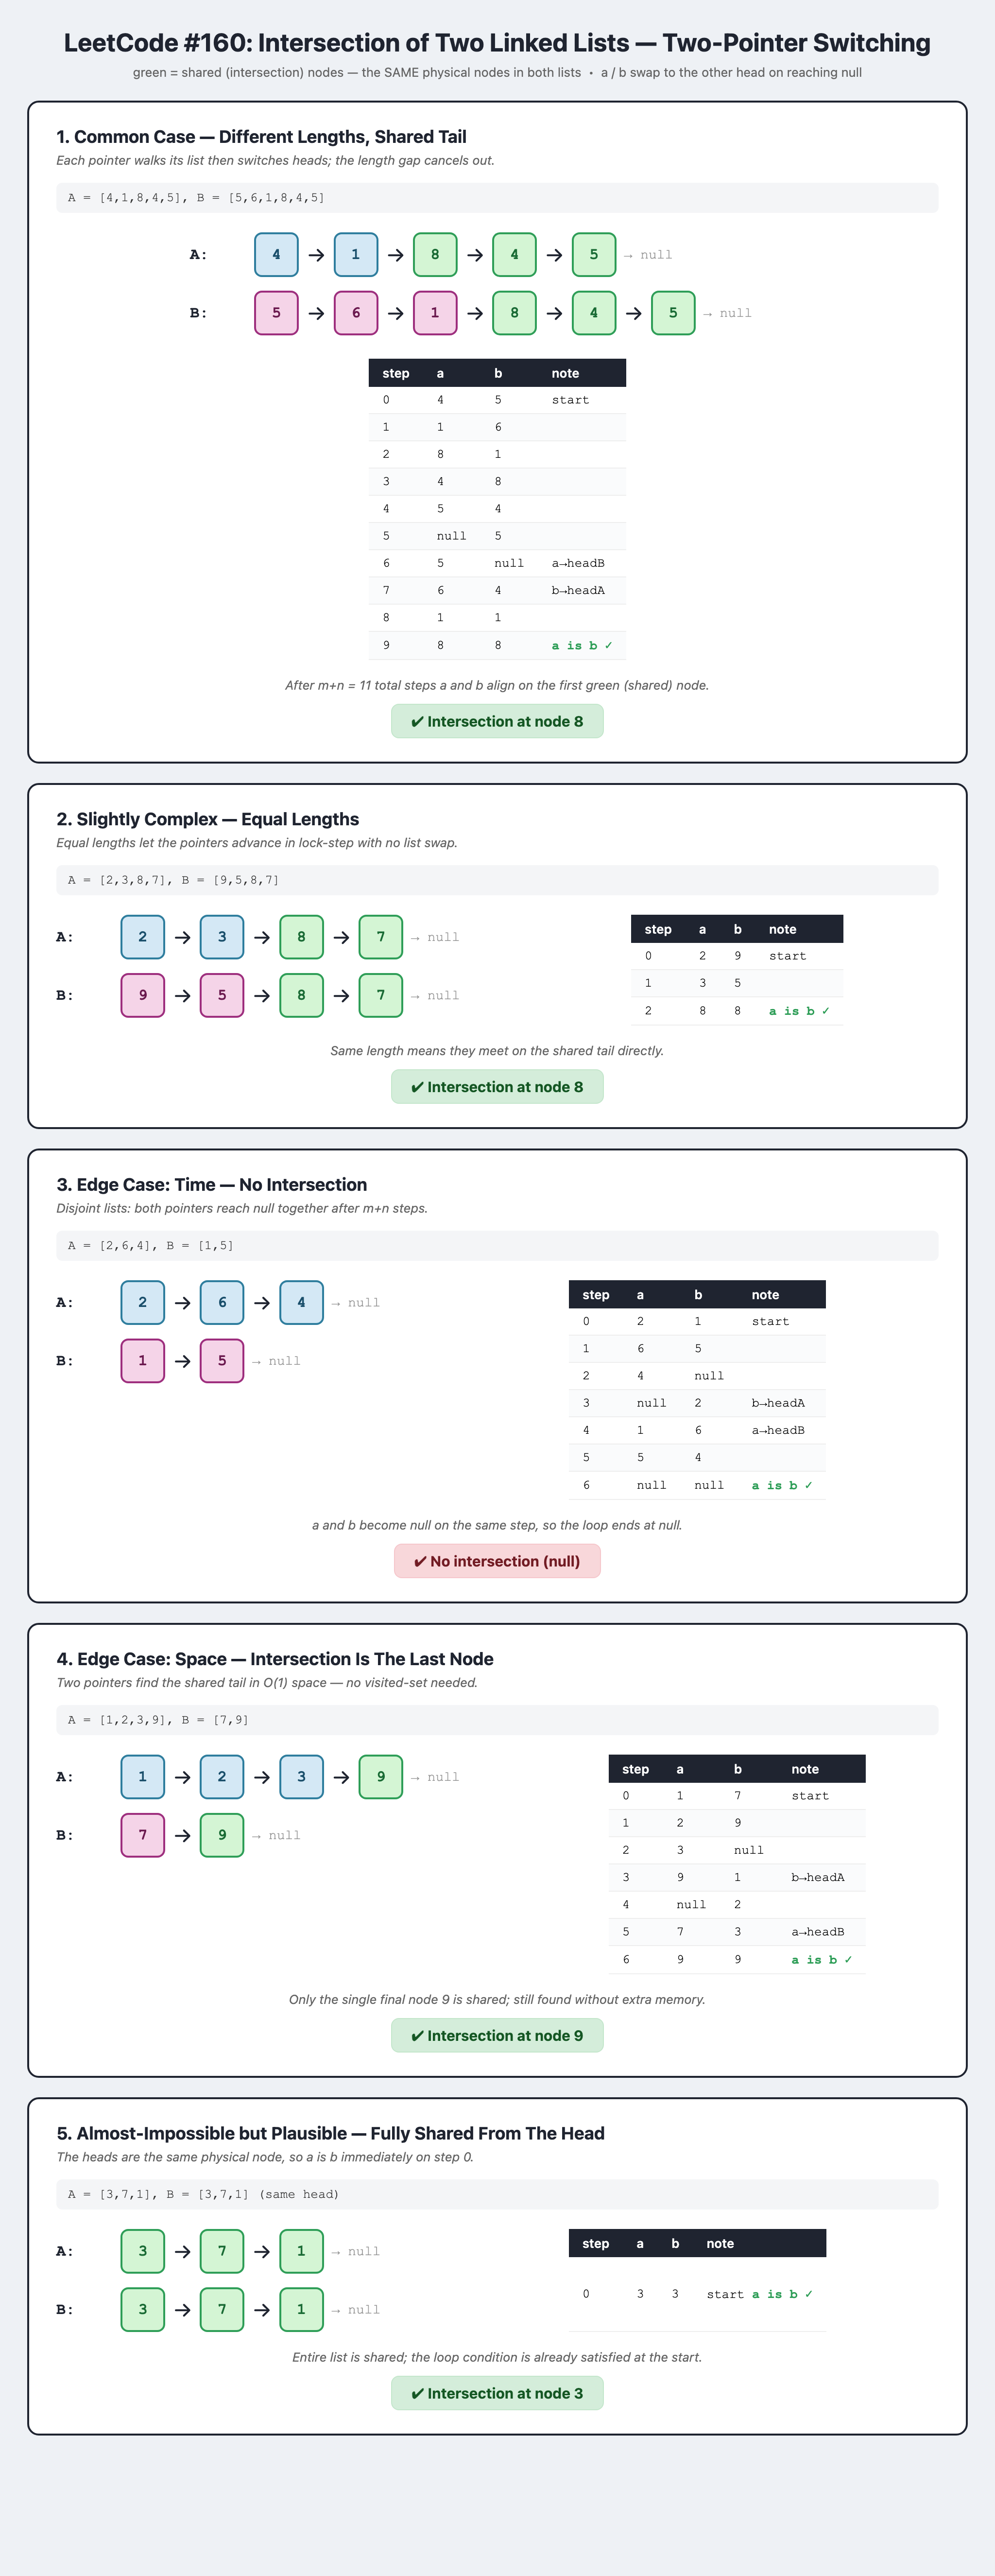